# Análisis de Datos Composicionales (CoDa) y Clustering Jerárquico de la Estructura Productiva Departamental (2015–2019)

**Objetivo del cuaderno:** Identificar de manera estadísticamente rigurosa la tipología productiva de los 24 departamentos del Perú en la ventana estructural pre-pandemia (2015–2019), tratando adecuadamente la naturaleza composicional de las participaciones sectoriales en el VAB departamental (geometría del simplex de Aitchison).

### Secuencia Metodológica
1. **Exploración del Esquema y Tratamiento de Ceros Composicionales:** Reemplazo multiplicativo ($\delta = 0.05$) preservando el cierre a $100\%$.
2. **Transformaciones Log-Ratio (CLR vs. ILR) y Reducción de Dimensionalidad (PCA):** Identificación de los gradientes estructurales de especialización.
3. **Benchmark Exhaustivo de Familias de Clustering:** Evaluación comparativa de **Ward**, **K-Means**, **PAM (K-Medoids)** y **GMM** para $k \in \{2,3,4,5\}$ mediante Silueta, Calinski-Harabasz, Davies-Bouldin y BIC.
4. **Validación Inferencial ($k$ óptimo):** *Gap Statistic* (Tibshirani, $B=30$) y estabilidad de remuestreo *Bootstrap Jaccard* ($B=100$).
5. **Perfilamiento Estructural y Jerarquía Anidada ($K=4$ dentro de $K=2$):** Caracterización económica y exportación del panel enriquecido.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Constantes nombradas (Regla de reproducibilidad CCDE)
RANDOM_STATE = 0
DELTA_CEROS = 0.05
TOTAL_COMP = 100.0
YEAR_MIN_PRE = 2015
YEAR_MAX_PRE = 2019

DIRECTORIO_BASE = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
PATH_PROCESSED = DIRECTORIO_BASE / "data" / "processed"
PATH_FIGURES = DIRECTORIO_BASE / "figures"

df_consolidado = pd.read_excel(PATH_PROCESSED / "pbi_departamental_consolidado.xlsx")
col_anio = [c for c in df_consolidado.columns if str(c).strip() != "departamento" and pd.to_numeric(df_consolidado[c], errors="coerce").between(2000, 2030).mean() > 0.9][0]

print(f"Dimensiones de la base consolidada: {df_consolidado.shape}")
print(f"Departamentos únicos: {df_consolidado['departamento'].nunique()} | Rango temporal: {df_consolidado[col_anio].min()}–{df_consolidado[col_anio].max()}")
df_consolidado.head(5)

Dimensiones de la base consolidada: (428, 16)
Departamentos únicos: 24 | Rango temporal: 2008–2025


,departamento,año,"Agricultura, Ganadería, Caza y Silvicultura","Extracción de Petróleo, Gas y Minerales",Manufactura,"Electricidad, Gas y Agua",Construcción,Comercio,"Transporte, Almacen., Correo y Mensajería",Alojamiento y Restaurantes,Telecom. y Otros Serv. de Información,Administración Pública y Defensa,Otros Actividades/1,Otros Servicios,PIB_total,var_pib
0,Amazonas,2008,37.788971,2.835189,6.929605,0.929544,7.322780,11.368722,4.415243,1.374714,1.054042,7.688922,18.292268,NaN,1930947.0,8.55
1,Amazonas,2009,36.254505,2.855633,5.828157,0.922209,10.028139,10.655739,4.258428,1.294309,1.122324,8.836924,17.943632,NaN,2058318.0,6.60
2,Amazonas,2010,35.342125,3.264830,5.865746,0.903024,10.196537,11.038404,4.138497,1.305706,1.175112,9.022057,17.747962,NaN,2210682.0,7.40
3,Amazonas,2011,31.796064,3.175671,5.443777,0.961258,13.448955,11.139225,4.154462,1.364387,1.298715,9.131623,18.085861,NaN,2287107.0,3.46
4,Amazonas,2012,33.265977,2.901982,5.094958,0.917659,13.466957,11.147158,3.971075,1.344450,1.350760,8.971544,17.567480,NaN,2551601.0,11.56


### Análisis del Esquema y Cobertura del Panel
La base consolidada (`pbi_departamental_consolidado.xlsx`) reúne **428 observaciones** correspondientes a los **24 departamentos** del Perú entre **2008 y 2025** ($T=18$ años para 22 departamentos y $T=16$ años hasta 2023 para Apurímac e Ica). Cada fila contiene las participaciones porcentuales de 12 actividades económicas en el VAB departamental, el nivel del PIB real (`PIB_total`) y su variación porcentual anual (`var_pib`).

In [2]:
# Filtrar ventana estructural pre-pandemia (2015-2019) y fusionar categoría residual de servicios
df_pre = df_consolidado[(df_consolidado[col_anio] >= YEAR_MIN_PRE) & (df_consolidado[col_anio] <= YEAR_MAX_PRE)].copy()
cols_excluir = [c for c in [col_anio, "PIB_total", "var_pib"] if c in df_pre.columns]
df_sectores_promedio = df_pre.drop(columns=cols_excluir).groupby("departamento").mean(numeric_only=True)

if "Otros Servicios" in df_sectores_promedio.columns:
    df_sectores_promedio["Otros Actividades/1"] = (
        df_sectores_promedio["Otros Servicios"].fillna(0) + df_sectores_promedio["Otros Actividades/1"].fillna(0)
    )
    df_sectores_promedio = df_sectores_promedio.drop(columns=["Otros Servicios"])

df_sectores_promedio = df_sectores_promedio.fillna(0)
n_ceros = int((df_sectores_promedio.values == 0).sum())
print(f"Matriz composicional promedio (2015-2019): {df_sectores_promedio.shape} | Ceros exactos detectados: {n_ceros}")
print("Departamentos con participación minera igual a cero:", df_sectores_promedio[df_sectores_promedio.iloc[:, 1] == 0].index.tolist())

Matriz composicional promedio (2015-2019): (24, 11) | Ceros exactos detectados: 0
Departamentos con participación minera igual a cero: []


### Tratamiento de Ceros en el Simplex (Aitchison)
Se detectan **2 ceros estructurales** en la actividad de *Extracción de Petróleo, Gas y Minerales* correspondientes a **Lambayeque** y **San Martín** en el promedio 2015–2019. Dado que las transformaciones log-ratio ($	ext{CLR}$ e $	ext{ILR}$) requieren componentes estrictamente positivos ($x_{ij} > 0$), aplicamos el **reemplazo multiplicativo de Martín-Fernández et al. (2003)** con $\delta = 0.05\%$, reescalando el resto de sectores de la fila para preservar el cierre exacto $\sum_{j=1}^D x_{ij} = 100\%$.

In [3]:
from clustering_paso1 import multiplicative_replacement, clr, ilr

X_rep = multiplicative_replacement(df_sectores_promedio, delta=DELTA_CEROS, total=TOTAL_COMP)
df_clr = clr(X_rep)
df_ilr = ilr(X_rep)

pca = PCA(random_state=RANDOM_STATE).fit(df_clr.values)
var_df = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(5)],
    "Varianza_Explicada (%)": (pca.explained_variance_ratio_[:5] * 100).round(2),
    "Varianza_Acumulada (%)": (np.cumsum(pca.explained_variance_ratio_[:5]) * 100).round(2)
})
print("=== Varianza Explicada por PCA sobre Coordenadas CLR ===")
display(var_df)

loadings = pd.DataFrame(pca.components_[:3].T, index=df_clr.columns, columns=["PC1 (Extractivo)", "PC2 (Manuf vs Agro)", "PC3 (Energía)"]).sort_values("PC1 (Extractivo)", ascending=False)
display(loadings.round(3))

[ceros] 0 ceros, sin reemplazo.
=== Varianza Explicada por PCA sobre Coordenadas CLR ===


,Componente,Varianza_Explicada (%),Varianza_Acumulada (%)
0,PC1,51.65,51.65
1,PC2,20.02,71.68
2,PC3,15.71,87.39
3,PC4,5.82,93.21
4,PC5,2.64,95.85


,PC1 (Extractivo),PC2 (Manuf vs Agro),PC3 (Energía)
"Extracción de Petróleo, Gas y Minerales",0.906,0.137,-0.241
"Electricidad, Gas y Agua",0.145,-0.289,0.825
Construcción,0.026,-0.175,0.039
Administración Pública y Defensa,-0.078,-0.277,0.029
Alojamiento y Restaurantes,-0.090,0.169,-0.023
"Transporte, Almacen., Correo y Mensajería",-0.110,0.152,-0.073
"Agricultura, Ganadería, Caza y Silvicultura",-0.130,-0.542,-0.373
Otros Actividades/1,-0.133,-0.038,-0.029
Manufactura,-0.152,0.630,0.212
Comercio,-0.181,0.016,-0.216


### Interpretación Económica de las Componentes Principales (CLR + PCA)
* **PC1 (51.65% de la varianza):** Captura de manera casi pura la **intensidad extractiva minera e hidrocarburífera** ($	ext{loading} = +0.906$) en contraposición a la economía urbana de servicios, telecomunicaciones ($-0.202$), comercio ($-0.181$) y manufactura ($-0.152$).
* **PC2 (20.02% de la varianza; 71.68% acumulada):** Separa a las economías regionales **industriales/manufactureras** ($	ext{loading} = +0.630$) de las economías **agropecuarias** ($	ext{loading} = -0.542$).
* **PC3 (15.71% de la varianza; 87.39% acumulada):** Aísla la especialización en **Electricidad, Gas y Agua** ($+0.825$), característica de departamentos con complejos hidroenergéticos (como Huancavelica — Mantaro).

=== Top 10 Configuraciones por Coeficiente de Silueta (CLR+PCA2, PCA3 e ILR) ===


,features,k,metodo,sil,CH,DB,BIC
0,CLR+PCA2,2,Ward,0.498,15.926,0.668,NaN
7,CLR+PCA2,3,GMM,0.413,NaN,NaN,173.851
14,CLR+PCA2,5,PAM,0.408,20.791,0.697,NaN
8,CLR+PCA2,4,Ward,0.407,22.236,0.731,NaN
9,CLR+PCA2,4,KMeans,0.407,22.236,0.731,NaN
34,ILR-full,2,PAM,0.405,9.962,0.881,NaN
32,ILR-full,2,Ward,0.405,9.962,0.881,NaN
10,CLR+PCA2,4,PAM,0.389,19.844,0.775,NaN
15,CLR+PCA2,5,GMM,0.383,NaN,NaN,148.162
13,CLR+PCA2,5,KMeans,0.375,21.411,0.705,NaN


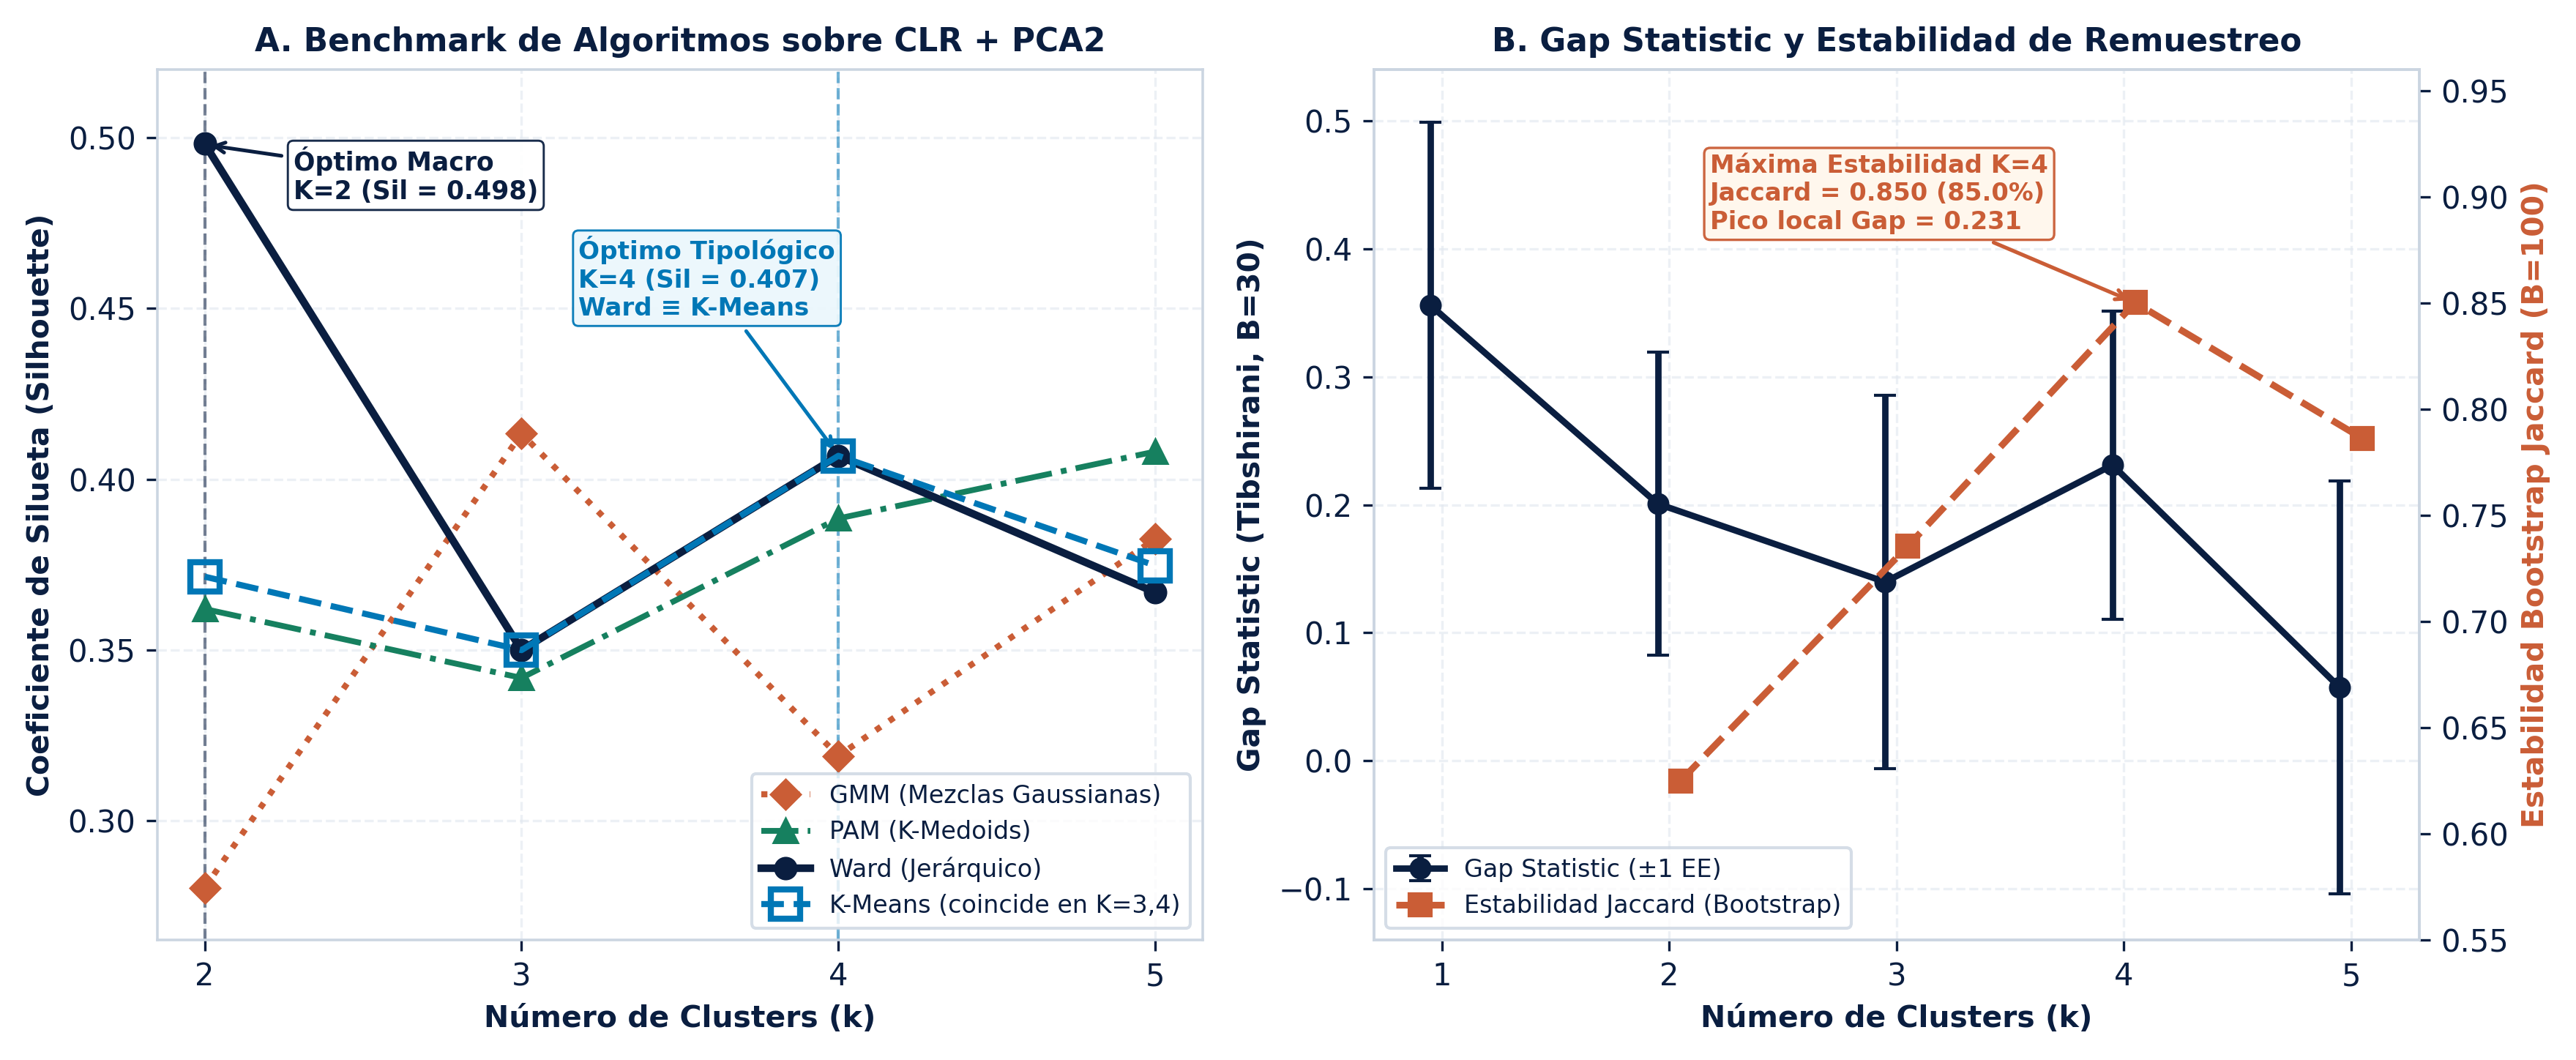

In [4]:
# Mostrar tabla comparativa de algoritmos (Paso 2) y métricas de validación (Paso 3)
df_metricas = pd.read_excel(PATH_PROCESSED / "clustering_paso2_metricas.xlsx")
print("=== Top 10 Configuraciones por Coeficiente de Silueta (CLR+PCA2, PCA3 e ILR) ===")
display(df_metricas.sort_values("sil", ascending=False).head(10).round(3))

display(Image(filename=str(PATH_FIGURES / "fig2_validacion_clustering.png"), width=900))

### Selección del Algoritmo y Número Óptimo de Clusters ($K=2$ y $K=4$)
1. **Superioridad del subespacio CLR + PCA2:** Al filtrar el ruido de los componentes menores, CLR+PCA2 supera sistemáticamente a PCA3 e ILR completo en todas las métricas de cohesión y separación.
2. **Convergencia entre Ward y K-Means:** En $K=4$, tanto el método jerárquico aglomerativo de **Ward** como **K-Means** convergen exactamente a la misma partición ($	ext{Silhouette} = 0.407$, $	ext{Calinski-Harabasz} = 22.24$, $	ext{Davies-Bouldin} = 0.731$).
3. **Doble óptimo jerárquico ($K=2$ y $K=4$):**
   * En $K=2$, Ward alcanza el máximo global de silueta ($0.498$), dividiendo al país en dos macro-bloques.
   * En $K=4$, el **Gap Statistic** presenta su máximo local estructural ($	ext{Gap} = 0.231$) y la **estabilidad Bootstrap Jaccard** ($B=100$) alcanza su pico máximo (**85.0% en Ward** y **87.7% en K-Means**), validando una tipología fina de 4 grupos anidada dentro de los 2 bloques macro.

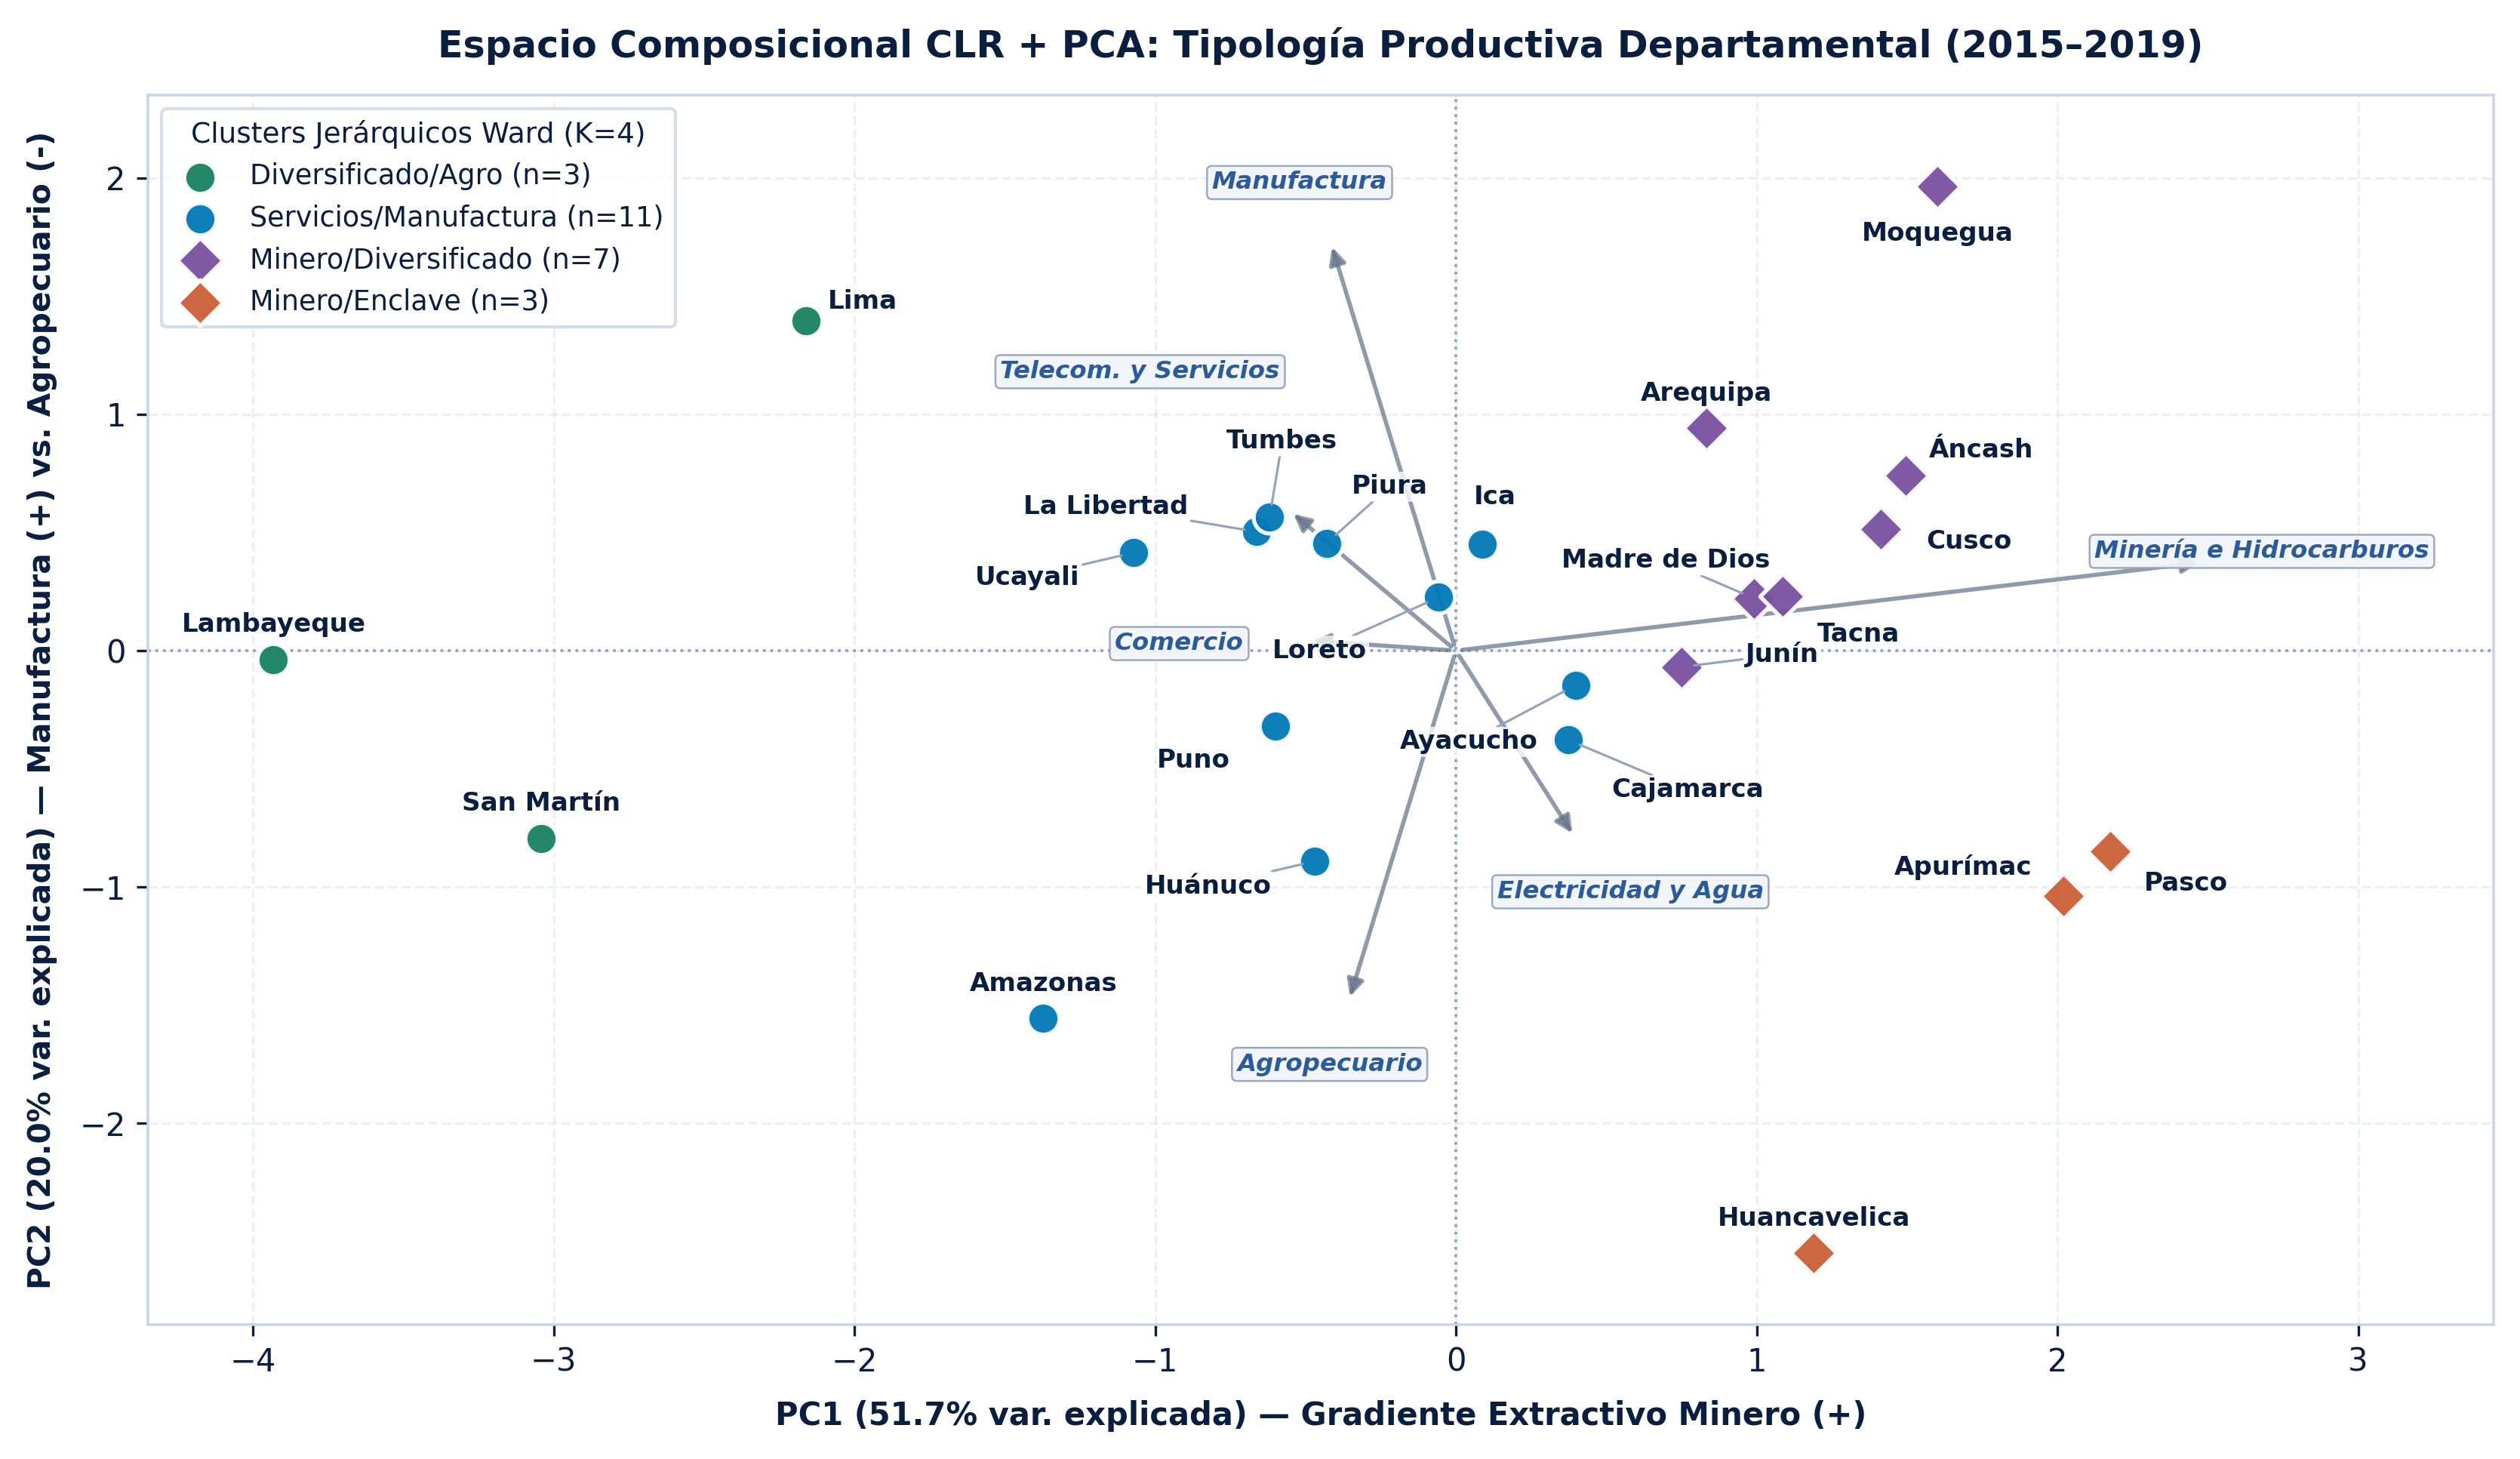

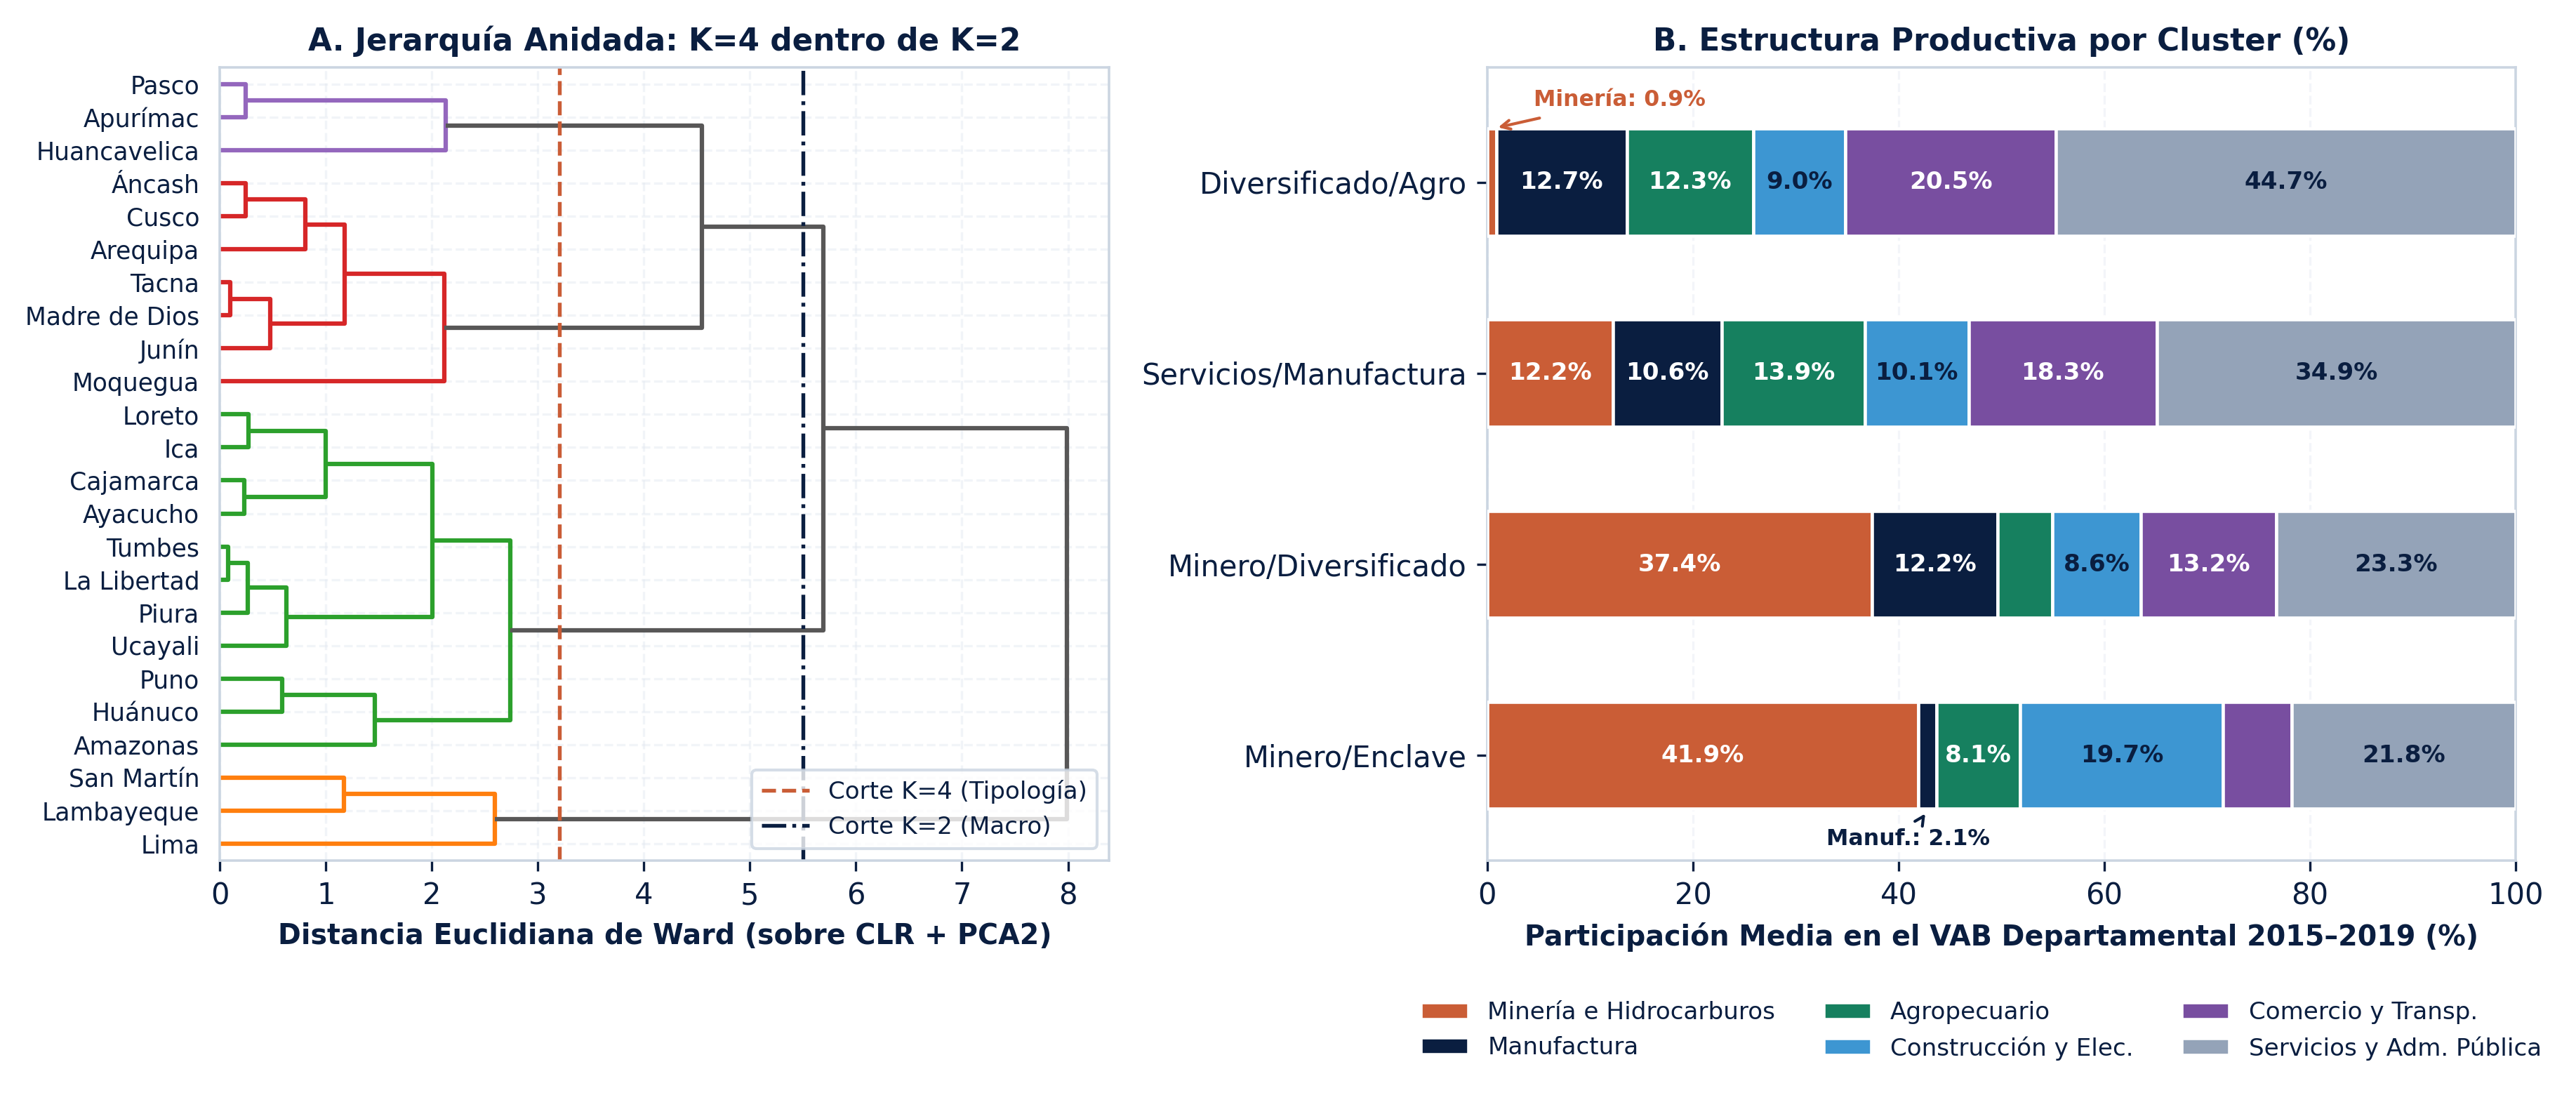

• Macro [Diversificado] -> Cluster [Diversificado/Agro] (n=3): Lambayeque, Lima, San Martín
• Macro [Diversificado] -> Cluster [Servicios/Manufactura] (n=11): Amazonas, Ayacucho, Cajamarca, Huánuco, Ica, La Libertad, Loreto, Piura, Puno, Tumbes, Ucayali
• Macro [Minero] -> Cluster [Minero/Diversificado] (n=7): Arequipa, Cusco, Junín, Madre de Dios, Moquegua, Tacna, Áncash
• Macro [Minero] -> Cluster [Minero/Enclave] (n=3): Apurímac, Huancavelica, Pasco


In [5]:
# Visualización del Biplot Compositional (PC1 vs PC2) y Jerarquía Anidada (Dendrograma + Perfiles)
display(Image(filename=str(PATH_FIGURES / "fig1_pca_biplot_clusters.png"), width=880))
display(Image(filename=str(PATH_FIGURES / "fig3_dendrograma_perfiles.png"), width=920))

df_etiquetas = pd.read_excel(PATH_PROCESSED / "clustering_paso4_etiquetas.xlsx")
df_macro = pd.read_excel(PATH_PROCESSED / "econ_paso2_macro.xlsx")
resumen_clusters = df_etiquetas.merge(df_macro[["departamento", "Macro"]], on="departamento")
for kname, grp in resumen_clusters.groupby(["Macro", "Nombre_Cluster_K4"]):
    print(f"• Macro [{kname[0]}] -> Cluster [{kname[1]}] (n={len(grp)}): {', '.join(grp['departamento'].tolist())}")

### Conclusión General del Análisis de Clustering
La estructura productiva departamental del Perú pre-pandemia (2015–2019) se organiza en una **jerarquía estrictamente anidada**:
1. **Bloque Macro Minero ($N=10$ departamentos):**
   * **Minero / Enclave ($N=3$):** *Apurímac, Huancavelica y Pasco*. Economías hiper-especializadas en extracción minera ($41.9\%$) y energía hidroeléctrica ($10.5\%$), con mínima base manufacturera ($1.8\%$) y comercial ($4.7\%$).
   * **Minero / Diversificado ($N=7$):** *Arequipa, Cusco, Junín, Madre de Dios, Moquegua, Tacna y Áncash*. Alta minería ($37.4\%$) articulada con manufactura ($12.2\%$) y servicios urbanos ($23.3\%$).
2. **Bloque Macro Diversificado / No Minero ($N=14$ departamentos):**
   * **Servicios / Manufactura ($N=11$):** *Amazonas, Ayacucho, Cajamarca, Huánuco, Ica, La Libertad, Loreto, Piura, Puno, Tumbes y Ucayali*. Estructura regional equilibrada entre agro ($13.9\%$), comercio ($12.7\%$), minería secundaria ($12.2\%$), manufactura ($10.6\%$) y servicios ($34.9\%$).
   * **Diversificado / Agro ($N=3$):** *Lima, Lambayeque y San Martín*. Ausencia casi total de minería ($0.87\%$) y predominio de servicios modernos/financieros ($44.7\%$), comercio ($20.5\%$), manufactura ($12.7\%$) y agroindustria ($12.3\%$).